<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_ap_quatrobarras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V, apêndice: o mecanismo de quatro barras

## Uma manivela, uma biela, um balancim: a curva do acoplador e o centro instantâneo como ponto fixo de uma pose

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X5_dualcomplexos.ipynb](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb))

**O mecanismo.** Quatro barras rígidas ligadas por quatro juntas de rotação formam um laço fechado: a **base** (fixa, de $O_2$ a $O_4$, comprimento $d$), a **manivela** (de $O_2$ a $A$, comprimento $a$), o **acoplador** (de $A$ a $B$, comprimento $b$) e o **balancim** (de $B$ a $O_4$, comprimento $c$). Gira-se a manivela, e o resto se move de um único jeito (escolhido o ramo de montagem). É o mecanismo mais estudado da cinemática: limpadores de para-brisa, pedais de bicicleta ergométrica, suspensões de carro, a perna do cavalo mecânico de Chebyshev.

**Em números complexos**, o laço fecha quando

$$a\,e^{i\theta_2}+b\,e^{i\theta_3}-c\,e^{i\theta_4}-d=0,$$

uma equação complexa (duas reais) para as duas incógnitas $\theta_3,\theta_4$, dado $\theta_2$. O **acoplador** é a barra interessante: ele não gira em torno de um ponto fixo, e a sua pose é um dual-complexo $q_3=\text{pose}(\theta_3,A)$. Um ponto preso a ele descreve a **curva do acoplador**, que pode ter formas surpreendentes (laços, cúspides, trechos quase retos).

**O que este notebook mostra.**
1. A posição por interseção de círculos, conferida pela equação do laço.
2. As velocidades angulares, por derivação da equação do laço, conferidas por diferenças finitas.
3. O **centro instantâneo** do acoplador como o **ponto fixo** da pose incremental $\Delta q=q_3(\theta_2+h)\,q_3(\theta_2)^{-1}$ (a dobradiça da porta do notebook V(a), seção 6), conferido pelo **teorema de Kennedy**: ele fica na interseção das retas $O_2A$ e $O_4B$.
4. A **condição de Grashof**, conferida por uma varredura numérica.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))

O2, O4 = 0j, 4.0 + 0j
a_, b_, c_, d_ = 1.0, 3.5, 3.0, 4.0

def posicao(t2, a=a_, b=b_, c=c_, d=d_, ramo=+1):
    """θ3, θ4 e os pontos A, B, pela interseção do círculo (A, b) com o círculo (O4, c). None se o laço não fecha."""
    A = a * np.exp(1j * t2); O4_ = d + 0j
    D = abs(O4_ - A)
    if D > b + c or D < abs(b - c):
        return None
    x = (b**2 - c**2 + D**2) / (2 * D)                  # distância de A ao pé da corda, ao longo de A→O4
    h = np.sqrt(max(b**2 - x**2, 0.0))
    u = (O4_ - A) / D
    B = A + x * u + ramo * h * 1j * u                   # ramo +1: montagem "aberta"
    return np.angle(B - A), np.angle(B - O4_), A, B

t3, t4, A, B = posicao(np.radians(60))
laco = a_ * np.exp(1j * np.radians(60)) + b_ * np.exp(1j * t3) - c_ * np.exp(1j * t4) - d_
confere("a equação do laço fecha (θ2 = 60°)", laco, 0, tol=1e-13)
confere("os comprimentos das barras se mantêm", [abs(B - A), abs(B - O4)], [b_, c_], tol=1e-13)
print(f"θ2 = 60°:  θ3 = {np.degrees(t3):.3f}°,  θ4 = {np.degrees(t4):.3f}°")

OK   a equação do laço fecha (θ2 = 60°):  diferença máxima = 4.44e-16
OK   os comprimentos das barras se mantêm:  diferença máxima = 0.00e+00
θ2 = 60°:  θ3 = 36.023°,  θ4 = 102.890°


## 1. Velocidades: derivar a equação do laço

Derivando a equação do laço no tempo, com $\omega_k=\dot\theta_k$:

$$i a\omega_2e^{i\theta_2}+i b\omega_3e^{i\theta_3}-i c\omega_4e^{i\theta_4}=0,$$

uma equação complexa **linear** em $\omega_3,\omega_4$. Separando parte real e imaginária, é um sistema $2\times2$. É o mesmo truque do jacobiano do braço (notebook V(b)): a cinemática de posição é não linear, a de velocidade é linear.

In [2]:
def velocidades(t2, w2=1.0):
    t3, t4, A, B = posicao(t2)
    M = np.array([[(1j * b_ * np.exp(1j * t3)).real, (-1j * c_ * np.exp(1j * t4)).real],
                  [(1j * b_ * np.exp(1j * t3)).imag, (-1j * c_ * np.exp(1j * t4)).imag]])
    rhs = -1j * a_ * w2 * np.exp(1j * t2)
    return np.linalg.solve(M, [rhs.real, rhs.imag])

t2, h = np.radians(60), 1e-6
w3, w4 = velocidades(t2)
p_mais, p_menos = posicao(t2 + h), posicao(t2 - h)
w3_df = wrap(p_mais[0] - p_menos[0]) / (2 * h); w4_df = wrap(p_mais[1] - p_menos[1]) / (2 * h)
print(f"com a manivela a 1 rad/s:  ω3 = {w3:.6f},  ω4 = {w4:.6f} rad/s")
confere("ω3 e ω4 pela equação do laço = diferenças finitas", [w3, w4], [w3_df, w4_df], tol=1e-7)

com a manivela a 1 rad/s:  ω3 = -0.211458,  ω4 = 0.147301 rad/s
OK   ω3 e ω4 pela equação do laço = diferenças finitas:  diferença máxima = 9.85e-11


## 2. O centro instantâneo do acoplador: o ponto fixo de uma pose

Entre dois instantes próximos, o acoplador sofre o deslocamento rígido $\Delta q=q_3(\theta_2+h)\,q_3(\theta_2)^{-1}$. Todo deslocamento rígido do plano que gira (ângulo $\Delta\theta\neq0$) é uma rotação em torno de **um** ponto, o seu ponto fixo: $e^{i\Delta\theta}p+t=p$, ou seja, $p=t/(1-e^{i\Delta\theta})$. Quando $h\to0$, esse ponto tende ao **centro instantâneo de rotação** do acoplador: naquele instante, o acoplador inteiro gira em torno dele, como uma porta em torno da dobradiça.

O **teorema de Kennedy** diz onde ele está sem conta nenhuma: na interseção das retas $O_2A$ (o ponto $A$ se move perpendicularmente à manivela) e $O_4B$ (idem para $B$ e o balancim). Os dois caminhos têm de dar o mesmo ponto.

In [3]:
def pose_acoplador(t2):
    t3, t4, A, B = posicao(t2)
    return pose(t3, A)

def centro_instantaneo(t2, h=1e-5):
    dq = pose_acoplador(t2 + h) * pose_acoplador(t2 - h).conj()
    return translacao(dq) / (1 - np.exp(1j * angulo(dq)))

def intersecao(p1, d1, p2, d2):
    """interseção das retas p1 + s·d1 e p2 + u·d2"""
    M = np.array([[d1.real, -d2.real], [d1.imag, -d2.imag]])
    s = np.linalg.solve(M, [(p2 - p1).real, (p2 - p1).imag])[0]
    return p1 + s * d1

for graus in [30, 60, 120, 200, 300]:
    t2 = np.radians(graus)
    _, _, A, B = posicao(t2)
    ci = centro_instantaneo(t2)
    kennedy = intersecao(O2, A - O2, O4, B - O4)
    print(f"θ2 = {graus:3d}°:  ponto fixo de Δq = {ci:.5f};   Kennedy = {kennedy:.5f}")
    confere(f"  ponto fixo = Kennedy em θ2 = {graus}°", ci, kennedy, tol=1e-5, relativo=True)

θ2 =  30°:  ponto fixo de Δq = 3.56517+2.05835j;   Kennedy = 3.56517+2.05835j
OK     ponto fixo = Kennedy em θ2 = 30°:  diferença relativa máxima = 5.82e-11
θ2 =  60°:  ponto fixo de Δq = 2.86454+4.96153j;   Kennedy = 2.86454+4.96153j
OK     ponto fixo = Kennedy em θ2 = 60°:  diferença relativa máxima = 7.27e-11
θ2 = 120°:  ponto fixo de Δq = 145.73580-252.42181j;   Kennedy = 145.73580-252.42181j
OK     ponto fixo = Kennedy em θ2 = 120°:  diferença relativa máxima = 2.27e-10
θ2 = 200°:  ponto fixo de Δq = 2.79957+1.01896j;   Kennedy = 2.79957+1.01896j
OK     ponto fixo = Kennedy em θ2 = 200°:  diferença relativa máxima = 4.01e-12
θ2 = 300°:  ponto fixo de Δq = -8.17883+14.16614j;   Kennedy = -8.17883+14.16614j
OK     ponto fixo = Kennedy em θ2 = 300°:  diferença relativa máxima = 3.83e-10


## 3. A curva do acoplador

Um ponto preso ao acoplador, nas coordenadas locais dele (origem em $A$, eixo real ao longo de $AB$), é levado ao mundo pela pose: $P=q_3\cdot p_{\text{local}}$ (a função `aplica`). Varrendo a manivela por uma volta inteira, $P$ desenha a curva do acoplador.

OK   a curva fecha depois de uma volta da manivela:  diferença máxima = 4.58e-16


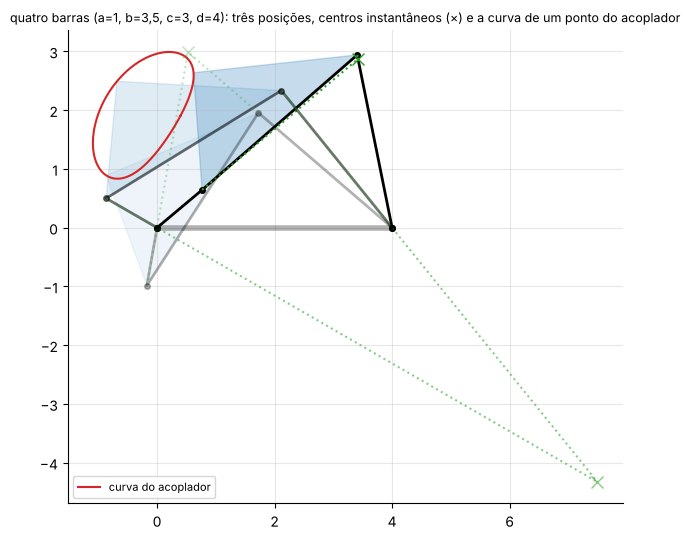

In [4]:
p_local = 1.2 + 1.6j                                 # um ponto do acoplador, fora da reta AB
angs = np.radians(np.linspace(0, 360, 721))
curva = np.array([aplica(pose_acoplador(t), p_local) for t in angs])
confere("a curva fecha depois de uma volta da manivela", curva[-1], curva[0], tol=1e-12)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(curva.real, curva.imag, "C3-", lw=1.5, label="curva do acoplador")
for graus, alfa in [(40, 1.0), (150, 0.55), (260, 0.3)]:
    t2 = np.radians(graus); _, _, A, B = posicao(t2)
    P = aplica(pose_acoplador(t2), p_local)
    ax.plot([O2.real, A.real, B.real, O4.real], [O2.imag, A.imag, B.imag, O4.imag], "k-o", ms=4, alpha=alfa, lw=2)
    ax.fill([A.real, B.real, P.real], [A.imag, B.imag, P.imag], color="C0", alpha=0.25 * alfa)
    ci = centro_instantaneo(t2)
    if abs(ci) < 12:
        ax.plot(ci.real, ci.imag, "x", color="C2", ms=9, alpha=alfa)
        ax.plot([A.real, ci.real], [A.imag, ci.imag], ":", color="C2", alpha=alfa)
        ax.plot([B.real, ci.real], [B.imag, ci.imag], ":", color="C2", alpha=alfa)
ax.plot([O2.real, O4.real], [O2.imag, O4.imag], "k-", lw=4, alpha=0.3)
ax.set_aspect("equal"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("quatro barras (a=1, b=3,5, c=3, d=4): três posições, centros instantâneos (×) e a curva de um ponto do acoplador", fontsize=9)
plt.tight_layout(); plt.show()

## 4. A condição de Grashof

Quando a manivela consegue dar a volta inteira? Com $s$ e $l$ a menor e a maior das quatro barras, e $p$, $q$ as outras duas, Grashof (1883) mostrou que **alguma** barra dá a volta completa se e só se

$$s+l\le p+q.$$

Se, além disso, a barra mais curta é a manivela, o mecanismo é **manivela–balancim** (a manivela gira, o balancim oscila); se a mais curta é a base, os dois braços giram (**dupla manivela**). Se a condição falha, nenhuma barra gira inteira: **duplo balancim**. A conferência abaixo varre $\theta_2$ e verifica, numericamente, se o laço fecha em todos os ângulos.

In [5]:
def manivela_gira(a, b, c, d):
    return all(posicao(t, a, b, c, d) is not None for t in np.linspace(0, 2 * np.pi, 2001))

def grashof(a, b, c, d):
    L = sorted([a, b, c, d]); return L[0] + L[3] <= L[1] + L[2]

casos = [(1.0, 3.5, 3.0, 4.0), (1.0, 2.0, 2.0, 2.5), (2.0, 2.0, 2.0, 1.0), (2.0, 3.0, 2.5, 4.0), (1.5, 4.0, 2.0, 4.0), (3.0, 1.0, 3.5, 4.0)]
print(" a     b     c     d    Grashof   a manivela (a) gira?   tipo")
for a, b, c, d in casos:
    g, gira = grashof(a, b, c, d), manivela_gira(a, b, c, d)
    menor = min(a, b, c, d)
    tipo = ({a: "manivela–balancim", d: "dupla manivela", b: "o acoplador gira; a e c só oscilam", c: "balancim–manivela (quem gira é c)"}[menor]) if g else "duplo balancim"
    print(f"{a:4.1f}  {b:4.1f}  {c:4.1f}  {d:4.1f}   {'sim' if g else 'não':5s}     {'sim' if gira else 'não':5s}               {tipo}")
    confere(f"  varredura concorda com Grashof", gira, g and menor in (a, d))   # a gira inteira se a ou a base é a mais curta

 a     b     c     d    Grashof   a manivela (a) gira?   tipo
 1.0   3.5   3.0   4.0   sim       sim                 manivela–balancim
OK     varredura concorda com Grashof:  diferença máxima = 0.00e+00


 1.0   2.0   2.0   2.5   sim       sim                 manivela–balancim
OK     varredura concorda com Grashof:  diferença máxima = 0.00e+00
 2.0   2.0   2.0   1.0   sim       sim                 dupla manivela
OK     varredura concorda com Grashof:  diferença máxima = 0.00e+00


 2.0   3.0   2.5   4.0   não       não                 duplo balancim
OK     varredura concorda com Grashof:  diferença máxima = 0.00e+00
 1.5   4.0   2.0   4.0   sim       sim                 manivela–balancim
OK     varredura concorda com Grashof:  diferença máxima = 0.00e+00
 3.0   1.0   3.5   4.0   sim       não                 o acoplador gira; a e c só oscilam
OK     varredura concorda com Grashof:  diferença máxima = 0.00e+00


**Leitura.** A posição por interseção de círculos fecha a equação do laço com erro de arredondamento, e as velocidades pela equação derivada coincidem com as diferenças finitas. O centro instantâneo calculado como **ponto fixo** da pose incremental do acoplador, um cálculo de dual-complexos que não sabe nada de mecanismos, cai exatamente na interseção das retas da manivela e do balancim, como manda o teorema de Kennedy. Na figura, as linhas pontilhadas verdes, de $A$ e de $B$ até o centro, são os prolongamentos da manivela e do balancim. A tabela de Grashof concorda com a varredura numérica nos seis casos: a manivela $a$ dá a volta inteira exatamente quando a condição vale **e** a barra mais curta é ela ou a base. No último caso a condição vale, mas a mais curta é o acoplador: ele gira inteiro em relação às vizinhas, e a manivela só oscila.

## Exercícios

1. **A perna de Chebyshev.** O mecanismo de Chebyshev com $d=2$, $a=1$, $b=c=2{,}5$ e o ponto do acoplador no prolongamento de $AB$, a uma distância $5$ de $A$, tem uma curva do acoplador com um trecho quase reto. Desenhe-a e meça o quanto o trecho se afasta de uma reta.
2. **O ângulo de transmissão.** O ângulo $\mu$ entre o acoplador e o balancim mede a qualidade da transmissão de força: perto de $0°$ ou $180°$, a manivela empurra o balancim quase pela haste, e o mecanismo trava. Calcule $\mu$ ao longo da volta e o seu mínimo. Projetistas pedem $\mu_{\min}\ge40°$; este mecanismo passa?
3. **O outro ramo.** Troque `ramo=+1` por `ramo=-1` (a montagem "cruzada"). A curva do acoplador muda? E o centro instantâneo continua no ponto de Kennedy?
4. **Síntese.** Escolha três posições desejadas para o acoplador (três poses $q$) e encontre o mecanismo de quatro barras que passa por elas (o problema de Burmester, com três posições, tem solução de régua e compasso). Dica: para cada um dos pontos $A$ e $B$, as três posições ficam numa circunferência; o centro dela é $O_2$ (ou $O_4$).